Employee turnover prediction Using Machine Learning approaches and performance analysis of ML algorithms with ***Primary dataset***.

In [ ]:
# python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, precision_recall_curve, average_precision_score
)
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.exceptions import NotFittedError
import pickle

sns.set_style('whitegrid')
plt.style.use('seaborn-v0_8-whitegrid')

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)



In [ ]:
# To mount google drive with the this file

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# To read .csv file from an specific path

df = pd.read_csv('/content/drive/MyDrive/dis/employee_turnover_pri.csv',index_col=0)
df = df.reset_index()
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 24 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   employee                                  24 non-null     int64 
 1   gender                                    24 non-null     object
 2   education_level                           24 non-null     object
 3   work_department                           24 non-null     object
 4   job_position                              24 non-null     object
 5   training_provided                         24 non-null     object
 6   work_overtime                             24 non-null     object
 7   working_for_the_company?                  24 non-null     object
 8   monthly_working_hours                     24 non-null     int64 
 9   monthly_overtime_hours                    24 non-null     int64 
 10  salary (yearly)                           24 non-nul

In [ ]:
df.head()

,employee,gender,education_level,work_department,job_position,training_provided,work_overtime,working_for_the_company?,monthly_working_hours,monthly_overtime_hours,...,satisfection_with_facilities,satisfection_with_safety,support_from_colleagues,relationship_with_manager/supervisor,satisfection_with_compensation,opportunities_for_career_ growth,recognition/appreciation_for_work,stay_with_company,turnover,factors_to_consider_leaving_organization
0,1,female,undergraduate,sales,sales executive,yes,no,less than 1 year,120,0,...,neutral,neutral,very supportive,average,neutral,average,often,yes,no,low compensation
1,2,female,undergraduate,sales,sales executive,yes,no,less than 1 year,140,0,...,neutral,neutral,neutrul,average,neutral,average,sometimes,no,yes,low compensation
2,3,female,undergraduate,other,assistant of office of student activities,yes,yes,1-2 year,270,70,...,satisfied,very satisfied,very supportive,excellent,satisfied,good,always,yes,no,excessive workload or stress
3,4,male,undergraduate,it,assistant officer,yes,yes,1-2 year,122,4,...,neutral,neutral,neutrul,average,dissatisfied,average,rarely,no,yes,poor work-life balance;difficult relationship ...
4,5,female,postgraduate,operation,coordinator,no,yes,1-2 year,136,40,...,very satisfied,very satisfied,unsupportive,poor,satisfied,poor,rarely,no,yes,lack of career growth;poor work-life balance;e...


**Exploratory Data Analysis (EDA)**

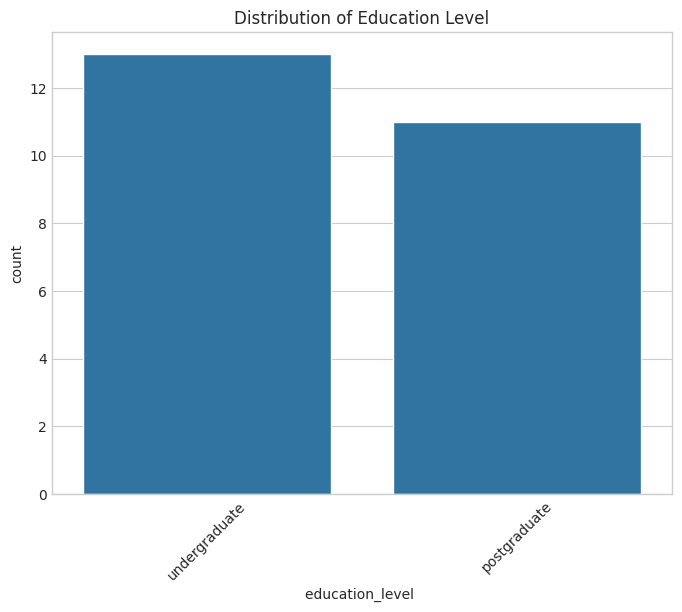

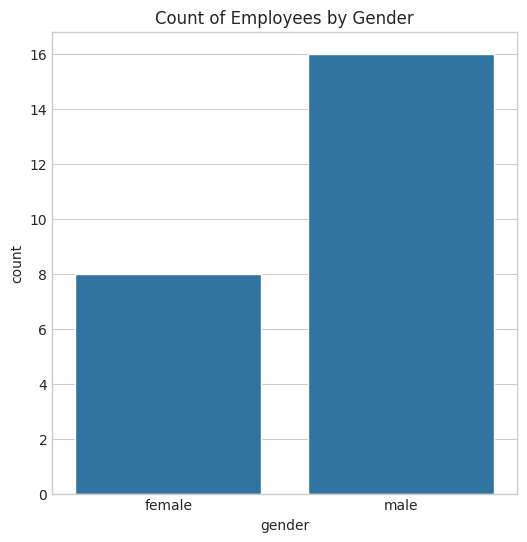

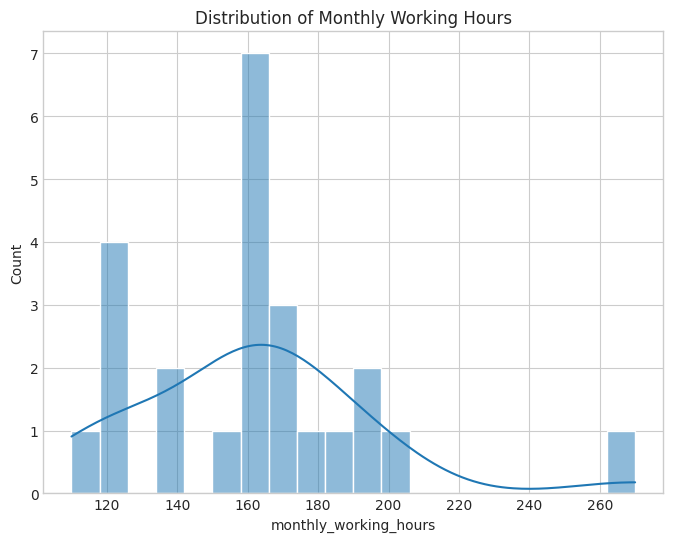

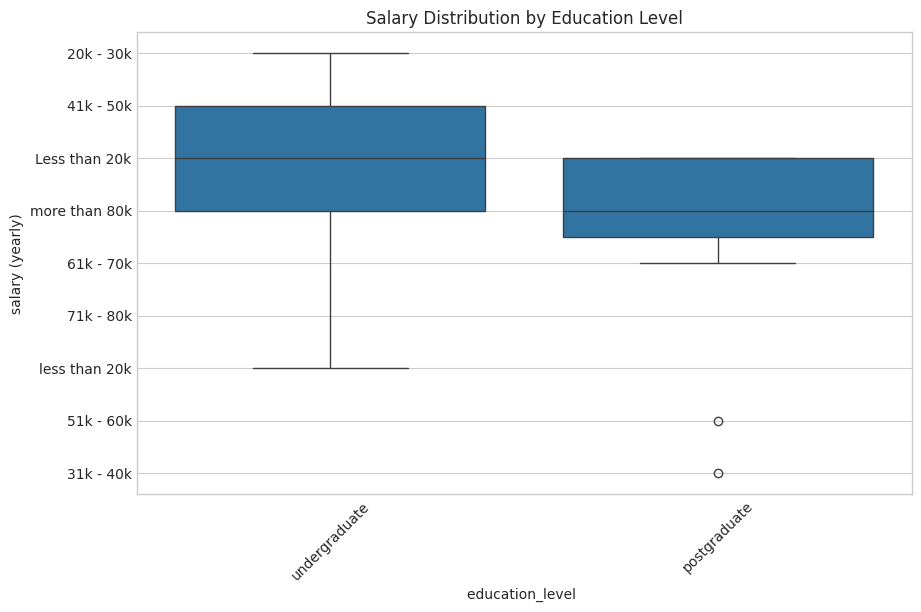

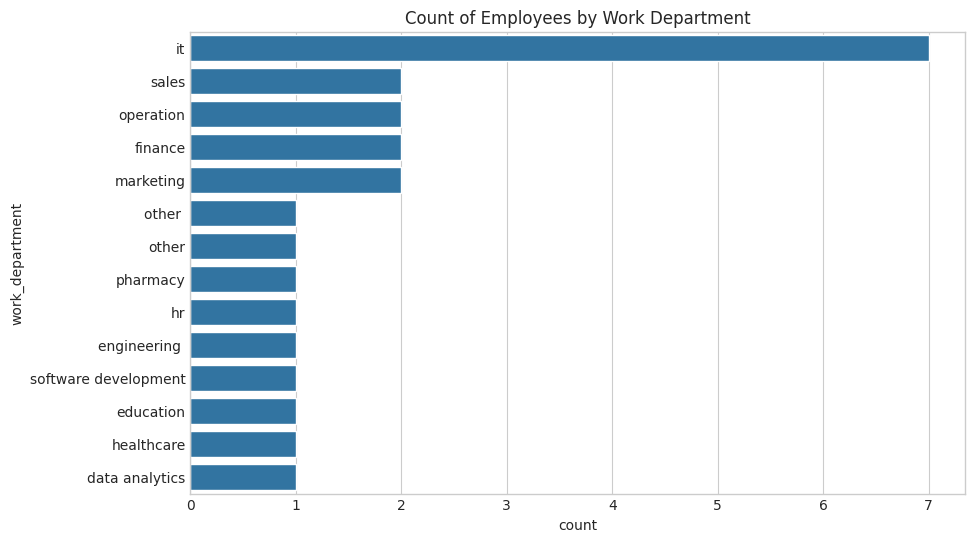

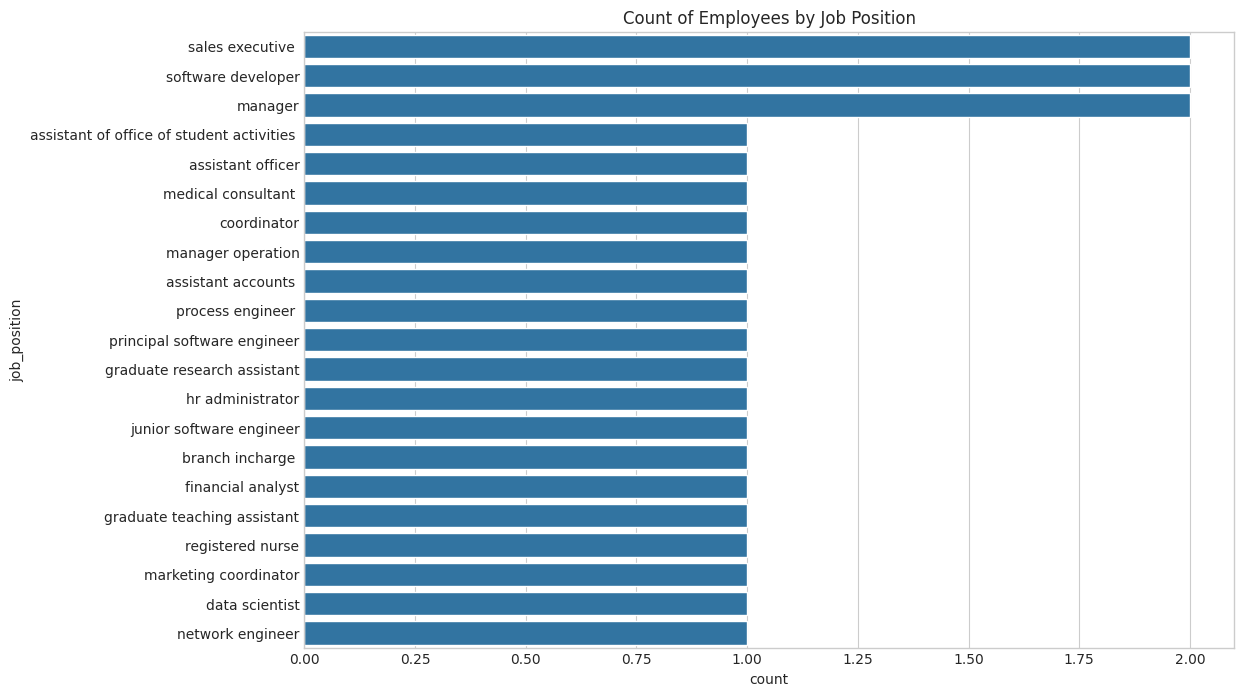

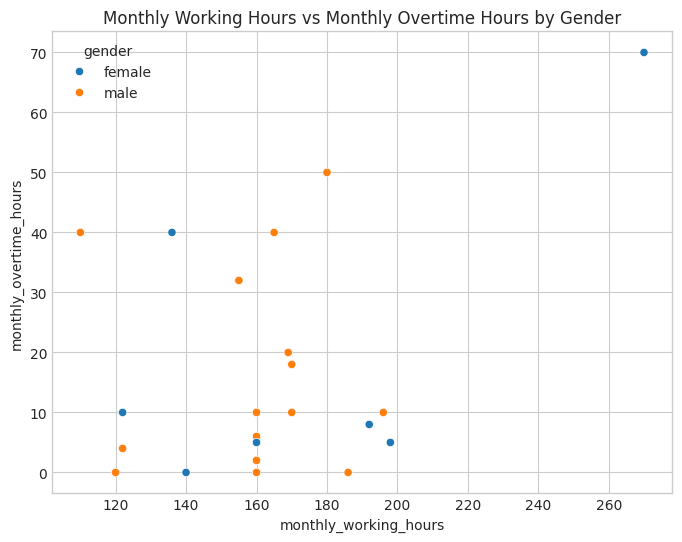

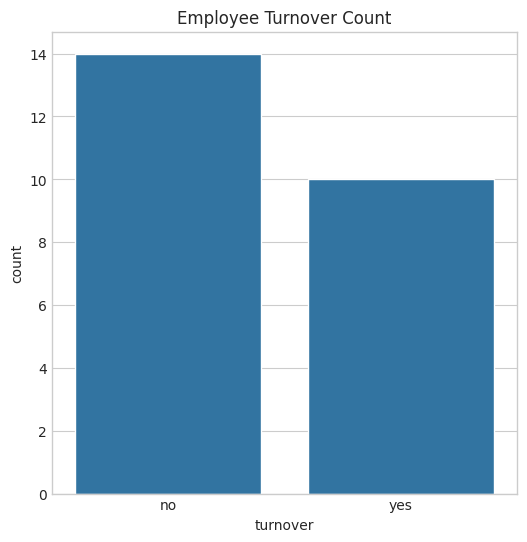

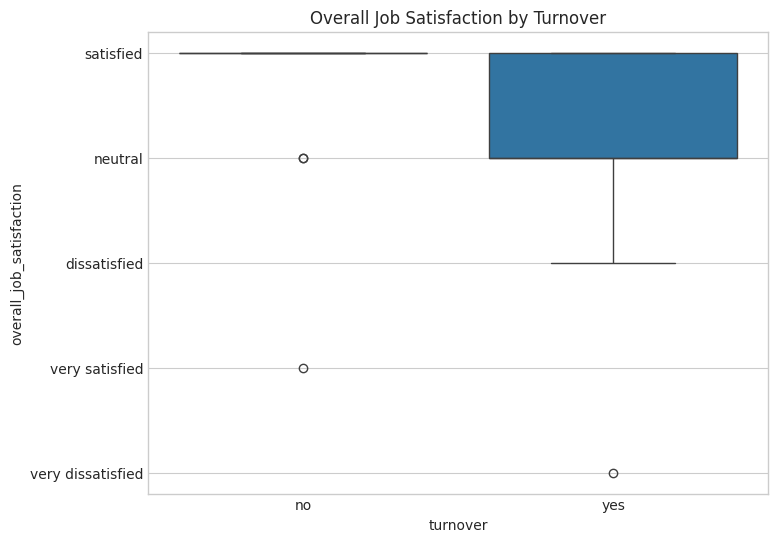

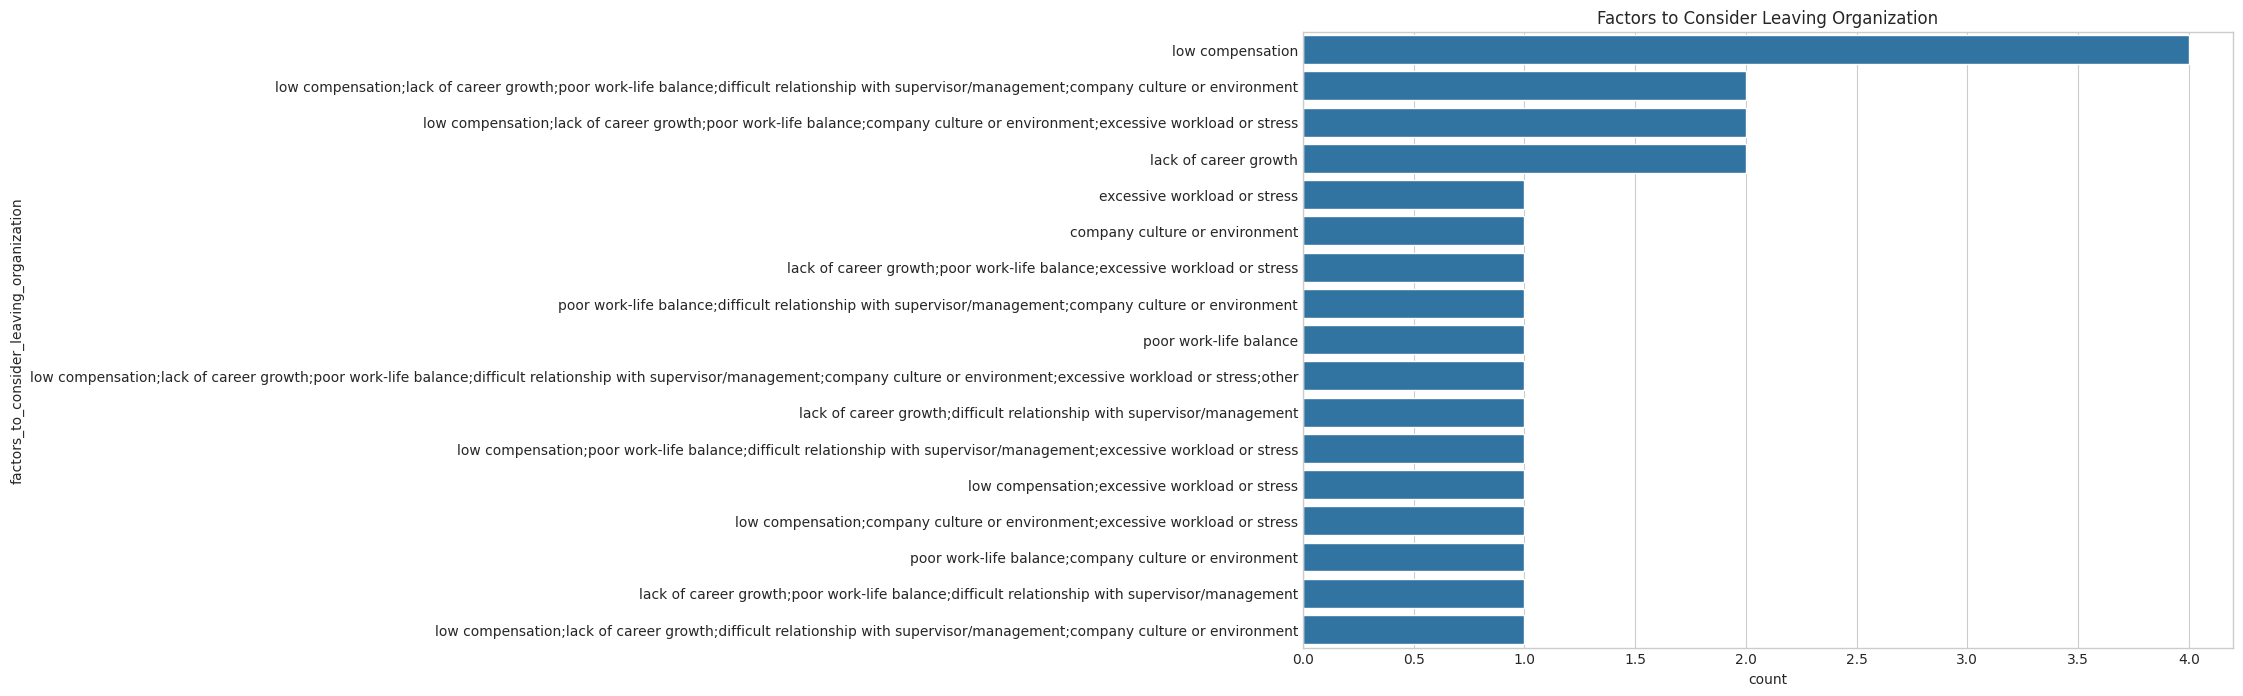

In [ ]:
# Exploratory Data Analysis (EDA 1)

# 1. Distribution of education_level
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='education_level ')
plt.title('Distribution of Education Level')
plt.xticks(rotation=45)
plt.show()

# 2. Count of employees by gender
plt.figure(figsize=(6, 6))
sns.countplot(data=df, x='gender')
plt.title('Count of Employees by Gender')
plt.show()

# 3. Distribution of monthly_working_hours
plt.figure(figsize=(8, 6))
sns.histplot(data=df, x='monthly_working_hours', bins=20, kde=True)
plt.title('Distribution of Monthly Working Hours')
plt.show()

# 4. Boxplot of salary by education_level
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='education_level ', y='salary (yearly)')
plt.title('Salary Distribution by Education Level')
plt.xticks(rotation=45)
plt.show()

# 5. Count of employees by work_department
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='work_department', order=df['work_department'].value_counts().index)
plt.title('Count of Employees by Work Department')
plt.show()

# 6. Count of employees by job_position
plt.figure(figsize=(12, 8))
sns.countplot(data=df, y='job_position', order=df['job_position'].value_counts().index)
plt.title('Count of Employees by Job Position')
plt.show()

# 7. Scatterplot: monthly_working_hours vs monthly_overtime_hours by gender
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='monthly_working_hours', y='monthly_overtime_hours', hue='gender')
plt.title('Monthly Working Hours vs Monthly Overtime Hours by Gender')
plt.show()

# 8. Count of employees by turnover
plt.figure(figsize=(6, 6))
sns.countplot(data=df, x='turnover')
plt.title('Employee Turnover Count')
plt.show()

# 9. Boxplot: overall_job_satisfaction by turnover
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='turnover', y='overall_job_satisfaction')
plt.title('Overall Job Satisfaction by Turnover')
plt.show()

# 10. Count of employees by factors_to_consider_leaving_organization
plt.figure(figsize=(12, 8))
sns.countplot(data=df, y='factors_to_consider_leaving_organization', order=df['factors_to_consider_leaving_organization'].value_counts().index)
plt.title('Factors to Consider Leaving Organization')
plt.show()


In [ ]:
df_eda = df.copy()      # copying main dataset
df_eda = df_eda.drop(columns=['factors_to_consider_leaving_organization'])
df_eda['turnover_numeric'] = df_eda['turnover'].apply(lambda x: 1 if x == 'yes' else 0)     # creating 'Turnover_numeric' column to hold numearical value (0/1) for Turnover feature.

print("Dataset Info for EDA:")
df_eda.info()
print("\nUnique values in turnover:", df_eda['turnover'].unique())
print("\nValue counts for turnover:\n", df_eda['turnover'].value_counts())

Dataset Info for EDA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 24 columns):
 #   Column                                Non-Null Count  Dtype 
---  ------                                --------------  ----- 
 0   employee                              24 non-null     int64 
 1   gender                                24 non-null     object
 2   education_level                       24 non-null     object
 3   work_department                       24 non-null     object
 4   job_position                          24 non-null     object
 5   training_provided                     24 non-null     object
 6   work_overtime                         24 non-null     object
 7   working_for_the_company?              24 non-null     object
 8   monthly_working_hours                 24 non-null     int64 
 9   monthly_overtime_hours                24 non-null     int64 
 10  salary (yearly)                       24 non-null     object
 11  promotion_co

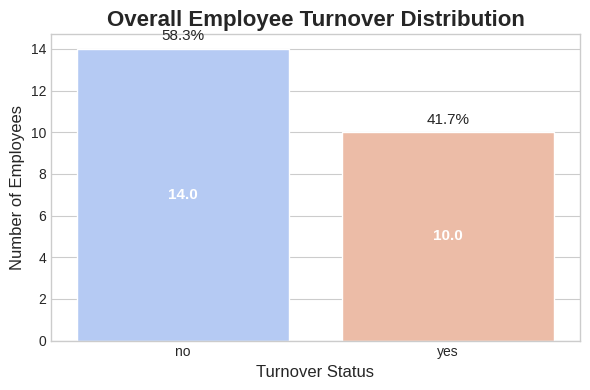

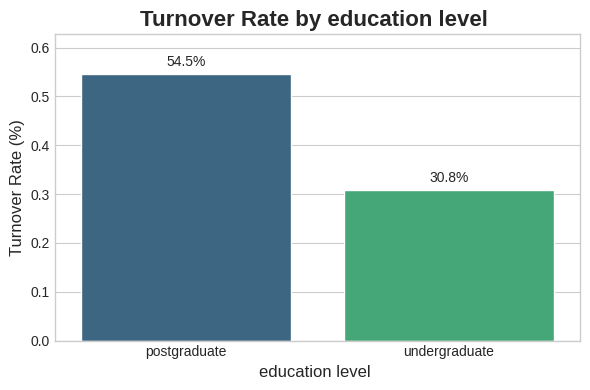

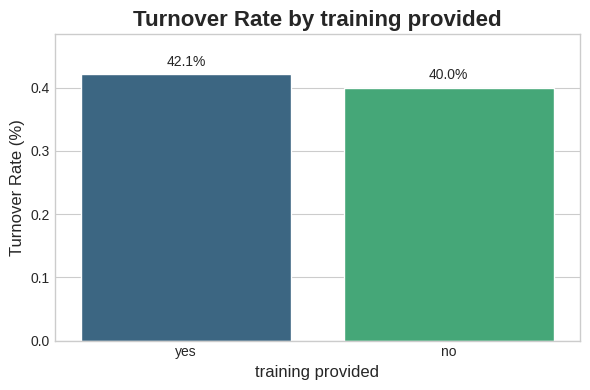

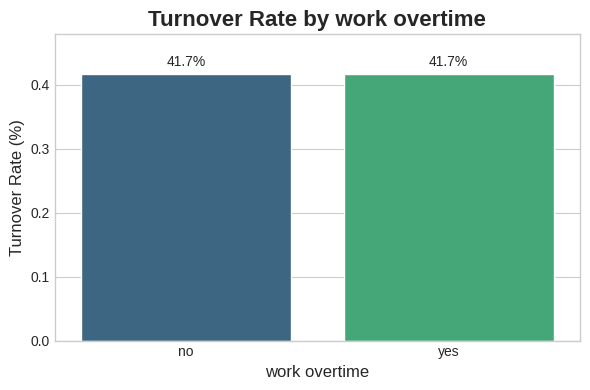

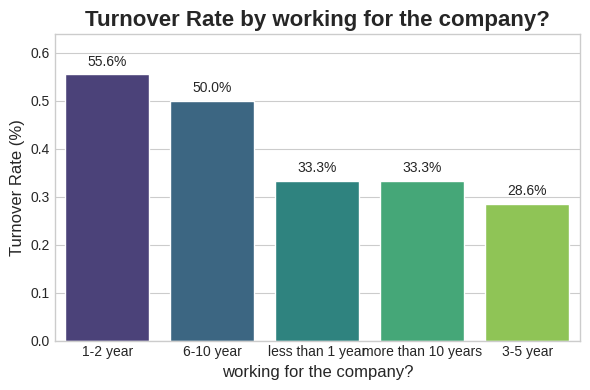

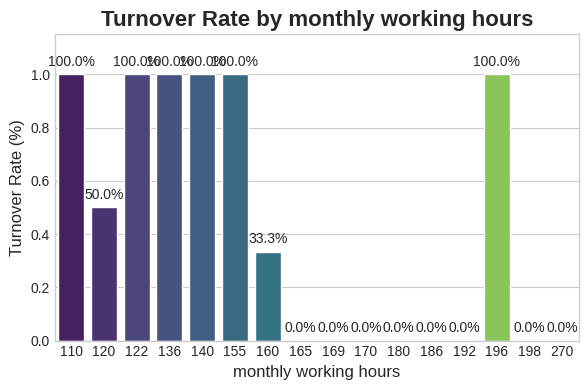

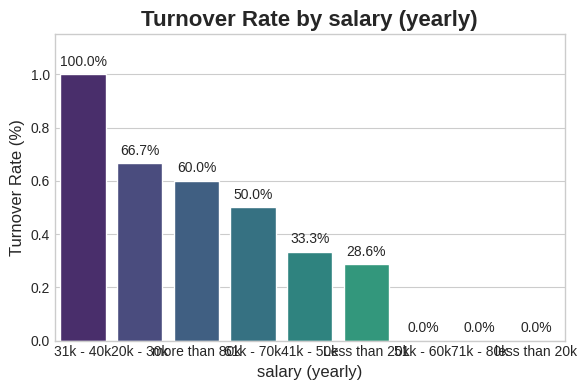

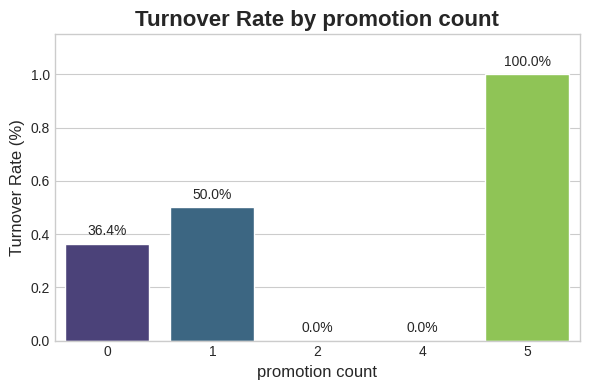

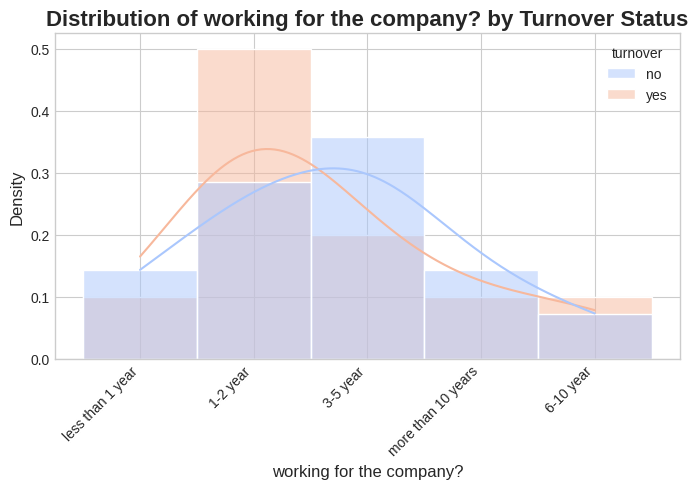

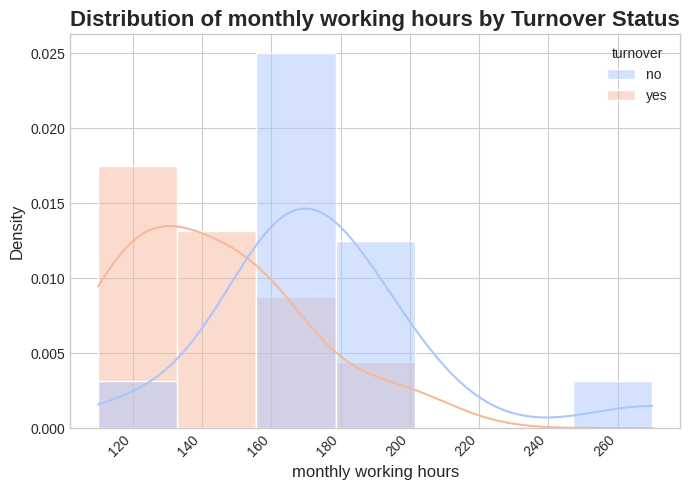

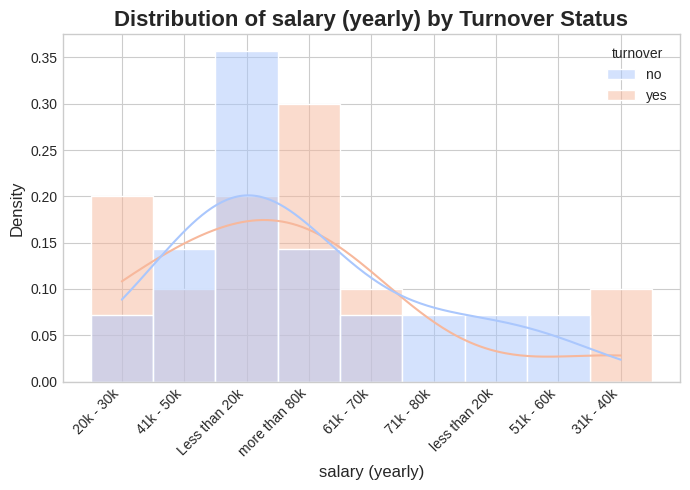

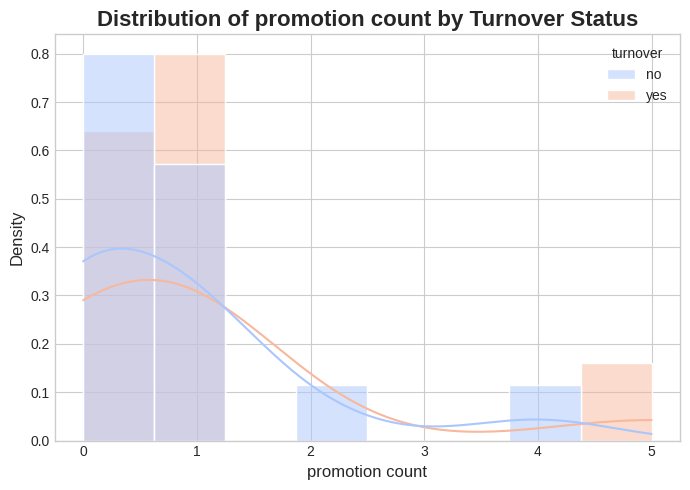

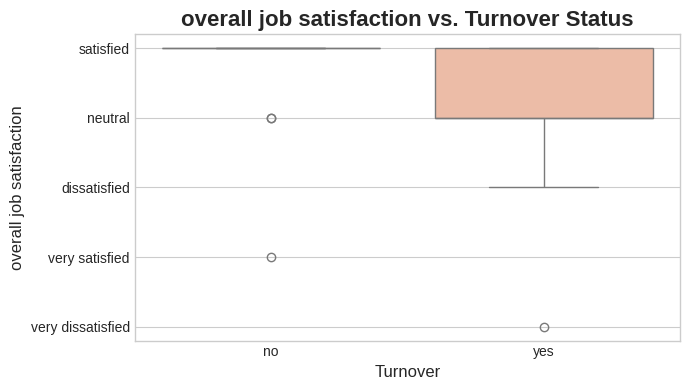

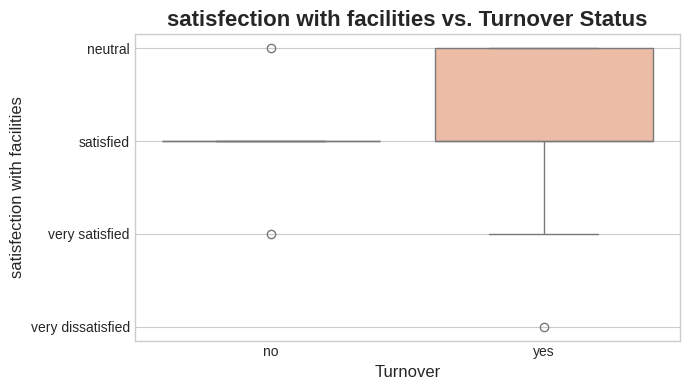

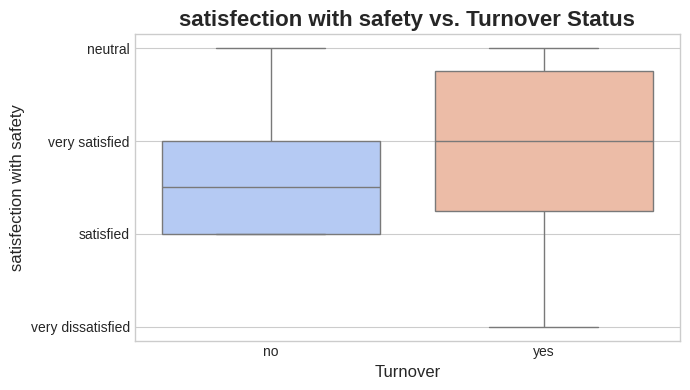

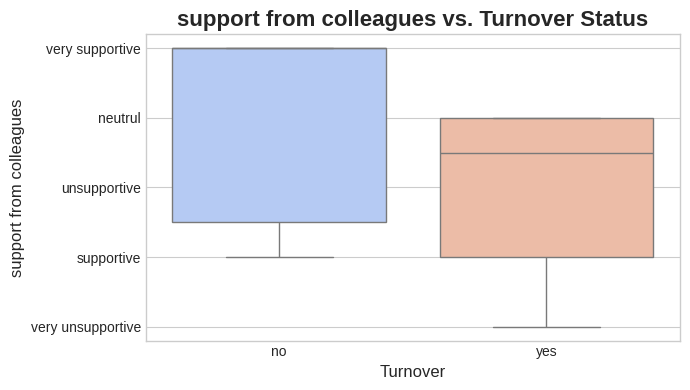

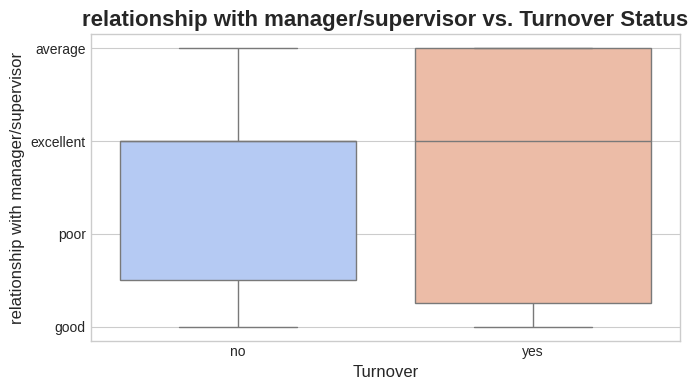

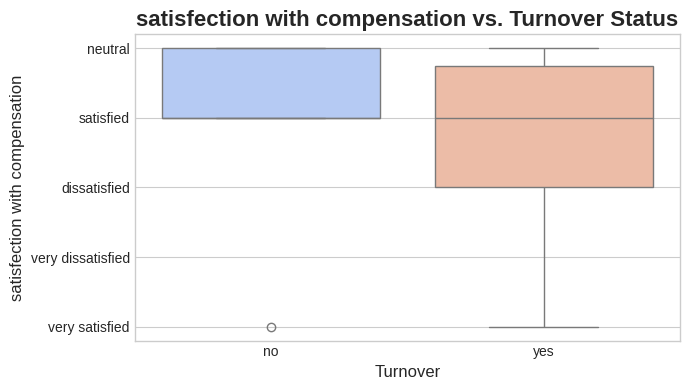

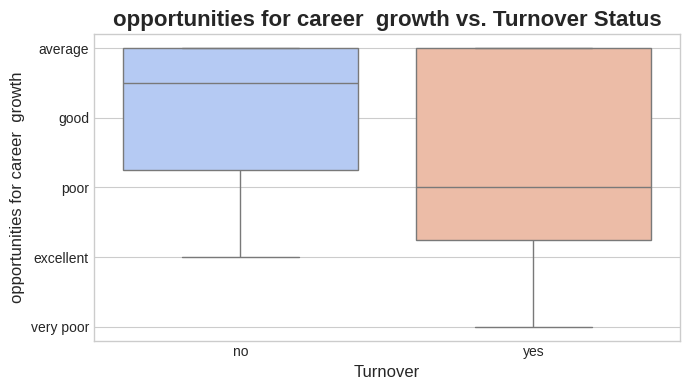

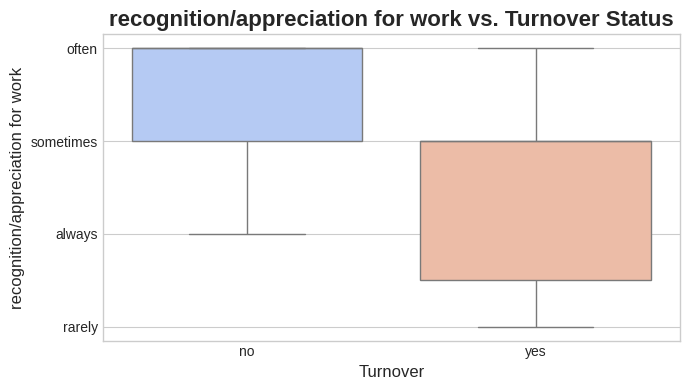

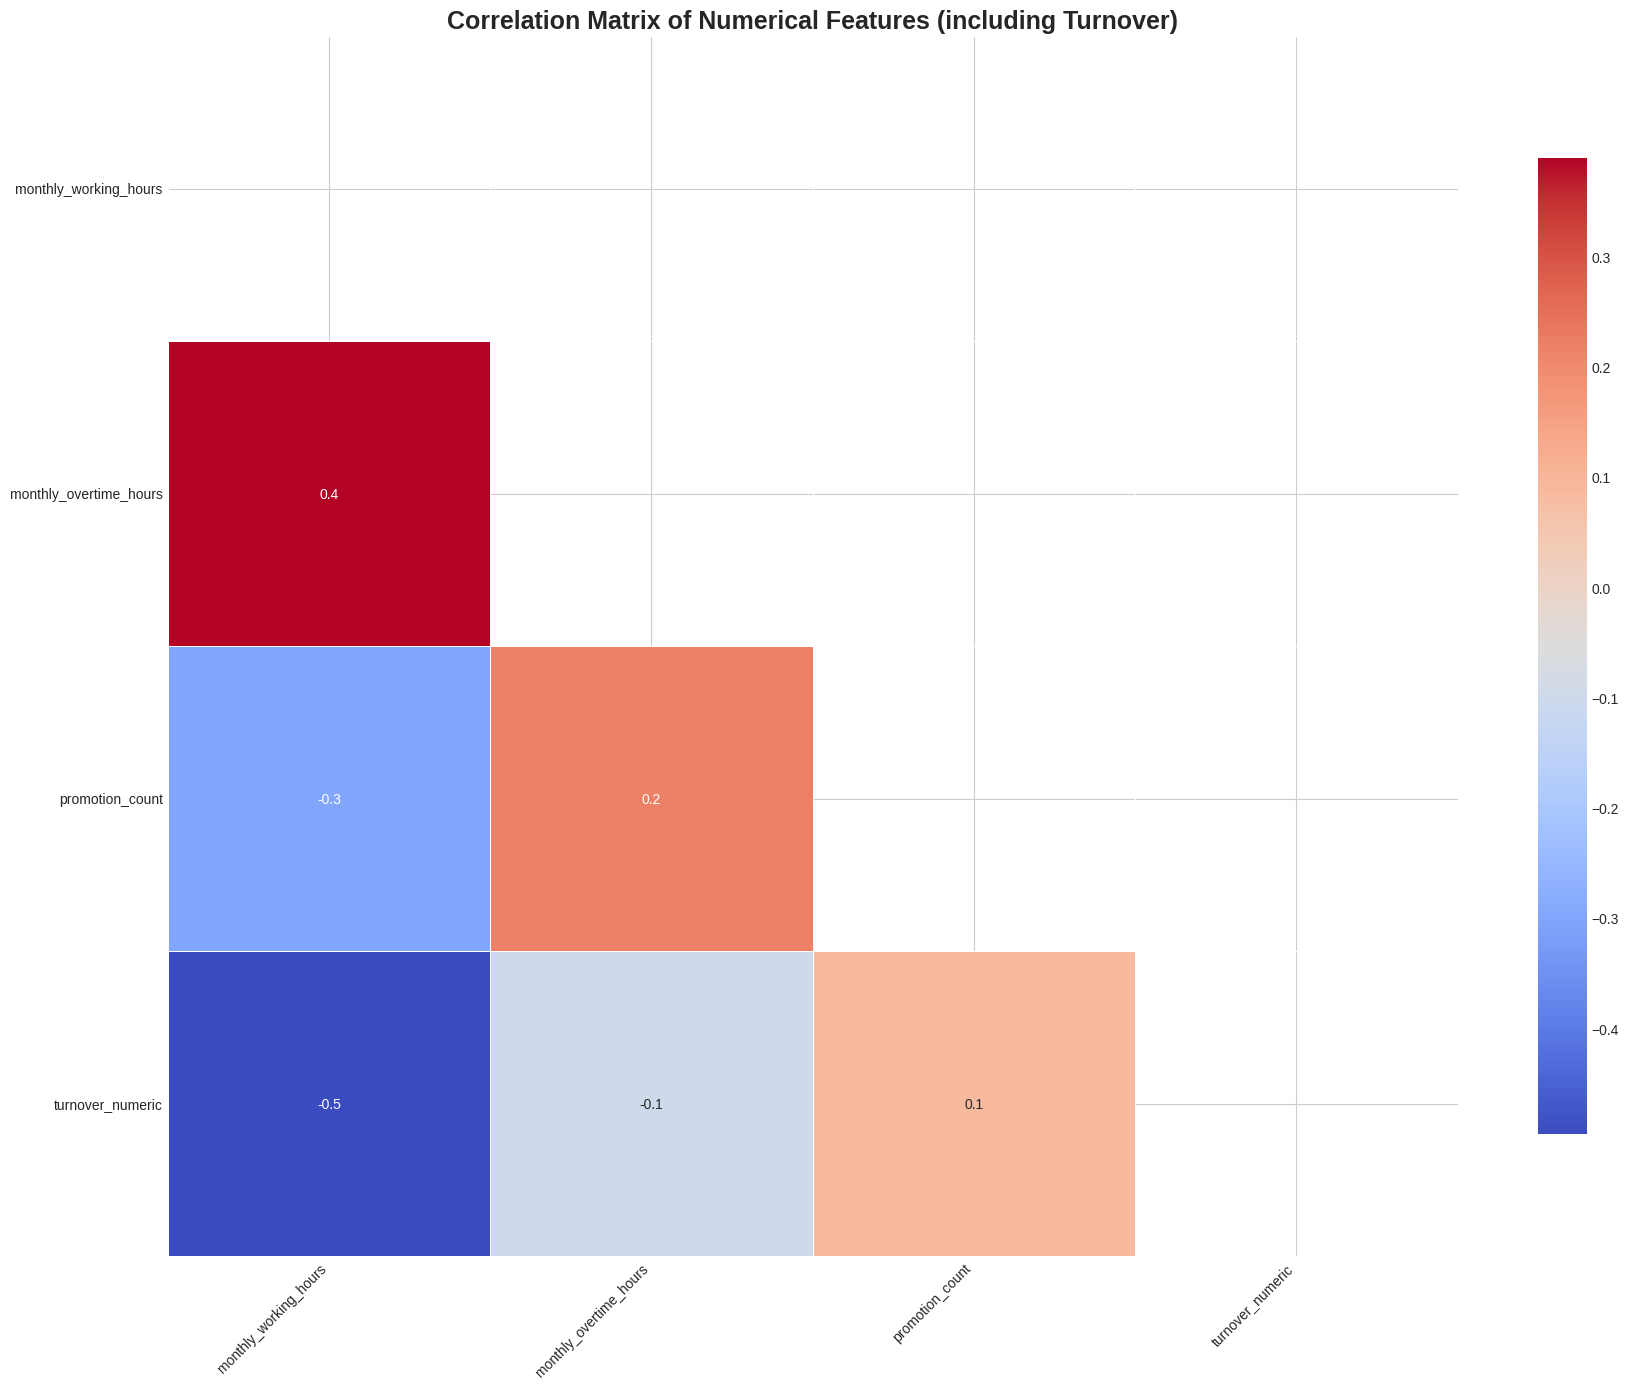

In [ ]:
# Exploratory Data Analysis (EDA 2)

# function to calculate employee turnover rate for categorical features
def plot_turnover_rate(df, column, title, rotation=0, figsize=(6, 4), order=None):
    plt.figure(figsize=figsize)
    turnover_rates = df.groupby(column)['turnover_numeric'].mean().sort_values(ascending=False)
    if order:
        turnover_rates = turnover_rates.reindex(order)
    ax = sns.barplot(x=turnover_rates.index, y=turnover_rates.values, palette='viridis', order=order)
    plt.title(f'Turnover Rate by {title}', fontsize=16, fontweight='bold')
    plt.xlabel(title, fontsize=12)
    plt.ylabel('Turnover Rate (%)', fontsize=12)
    plt.xticks(rotation=rotation, ha='right' if rotation > 0 else 'center')
    plt.ylim(0, max(turnover_rates.values) * 1.15)
    for p in ax.patches:
        ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 9),
                    textcoords='offset points', fontsize=10)
    plt.tight_layout()
    plt.show()

# function to calculate employee turnover rate for numerical features
def plot_distribution_numerical(df, column, title, rotation, figsize=(7, 5)):
    plt.figure(figsize=figsize)
    sns.histplot(data=df, x=column, hue='turnover', kde=True, stat='density', common_norm=False, palette='coolwarm')
    plt.title(f'Distribution of {title} by Turnover Status', fontsize=16, fontweight='bold')
    plt.xlabel(title, fontsize=12)
    plt.ylabel('Density', fontsize=12)
    plt.xticks(rotation=rotation, ha='right' if rotation > 0 else 'center')
    plt.tight_layout()
    plt.show()

# function to compare (boxplot) turnover status with numerical/ordinal features
def plot_boxplot_numerical(df, column, title, figsize=(7, 4)):
    plt.figure(figsize=figsize)
    sns.boxplot(data=df, x='turnover', y=column, palette='coolwarm')
    plt.title(f'{title} vs. Turnover Status', fontsize=16, fontweight='bold')
    plt.xlabel('Turnover', fontsize=12)
    plt.ylabel(title, fontsize=12)
    plt.tight_layout()
    plt.show()


# Overall Turnover Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_eda, x='turnover', palette='coolwarm', order=df_eda['turnover'].value_counts().index)
plt.title('Overall Employee Turnover Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Turnover Status', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
total = len(df_eda)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=11)
    ax.annotate(f'{p.get_height()}', (x, y/2), ha='center', va='center', fontsize=11, color='white', fontweight='bold')
plt.tight_layout()
plt.show()


# Turnover Rate by Categorical Features
categorical_features = ['education_level ', 'training_provided', 'work_overtime', 'working_for_the_company?',
                        'monthly_working_hours', 'salary (yearly)', 'promotion_count']
for col in categorical_features:
    plot_turnover_rate(df_eda, col, col.replace('_', ' '))


# Distribution of Numerical Features by Turnover
numerical_features_dist = ['working_for_the_company?', 'monthly_working_hours', 'salary (yearly)', 'promotion_count']
for col in numerical_features_dist:
    rotation = 0 if col == 'promotion_count' else 45
    plot_distribution_numerical(df_eda, col, col.replace('_', ' '), rotation)


# Box Plots of Numerical/Ordinal Features by Turnover
numerical_features_box = ['overall_job_satisfaction', 'satisfection_with_facilities', 'satisfection_with_safety',
                          'support_from_colleagues', 'relationship_with_manager/supervisor',
                          'satisfection_with_compensation', 'opportunities_for_career_ growth', 'recognition/appreciation_for_work',
                          ]
for col in numerical_features_box:
    plot_boxplot_numerical(df_eda, col, col.replace('_', ' '))



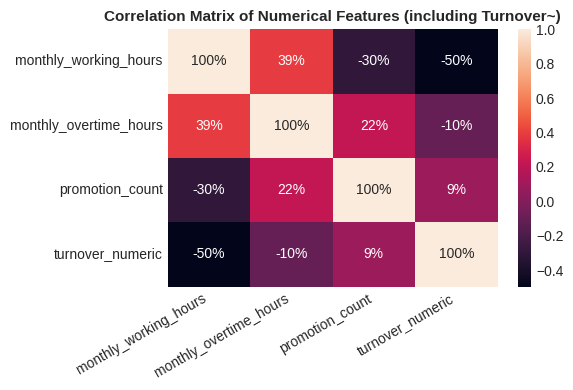

In [ ]:
# Correlation Heatmap to sea co-relation between features and turnover
plt.figure(figsize=(6, 4))
numerical_cols_for_corr = df_eda.select_dtypes(include=np.number).columns.tolist()
if 'employee' in numerical_cols_for_corr:       # to drop employee column that contains employee ID
    numerical_cols_for_corr.remove('employee')
correlation_matrix = df_eda[numerical_cols_for_corr].corr()
mask = np.triu(correlation_matrix)
sns.heatmap(correlation_matrix, annot=True, fmt='.0%')
plt.title('Correlation Matrix of Numerical Features (including Turnover~)', fontsize=11, fontweight='bold')

plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Data preprocessing**

In [ ]:
# Data loading and preprocessing
# Define target column/variable and feature matrix

target = 'turnover'             # defining target variable
features = df.drop(columns=[target, 'employee']).columns
X = df[features]
y = df[target].apply(lambda x: 1 if x == 'yes' else 0)

# Separate categorical and numerical features
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

# Preprocessing pipelines
categorical_transformer = OneHotEncoder(handle_unknown='ignore', drop='first')
numerical_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Apply preprocessing to X
X_preprocessed = preprocessor.fit_transform(X)
print(type(X_preprocessed), X_preprocessed.shape)

X_resampled, y_resampled = X_preprocessed, y

<class 'scipy.sparse._csr.csr_matrix'> (24, 99)


In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.25, random_state=42, stratify=y_resampled)


**ML classifeirs/model training and analysis**

In [ ]:
# defining a function to train model and getting the performance matrices

results = {}        #   to save resualt value for each ML algorithm/model
print("--- Model Training and Evaluation start ---")
# for name, model_pipeline in models.items():
def train_model(name, model_pipeline):
    print(f"Training {name}...")
    model_pipeline.fit(X_train, y_train)
    print(f"Evaluating {name}...")
    y_train_pred = model_pipeline.predict(X_train)
    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]


    train_accuracy = accuracy_score(y_train, y_train_pred)      # getting training accuracy
    accuracy = accuracy_score(y_test, y_pred)                   # overall test accuracy
    precision = precision_score(y_test, y_pred)                 # positive prediction correcness
    recall = recall_score(y_test, y_pred)                       # positive case detection
    f1 = f1_score(y_test, y_pred)                               # precision-recall balance or overall classification quality
    roc_auc = roc_auc_score(y_test, y_prob)                     # class separation ability

    results[name] = {                           # saving ML model's performance for later comparision
        "Train Accuracy": train_accuracy,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC AUC": roc_auc
    }

    print(f"\n{name} Performance:")
    print(f" Train Accuracy: {train_accuracy:.4f}")
    print(f" Test Accuracy: {accuracy:.4f}")
    print(f" Precision: {precision:.4f}")
    print(f" Recall: {recall:.4f}")
    print(f" F1-Score: {f1:.4f}")
    print(f" ROC AUC: {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("-" * 30)

    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

--- Model Training and Evaluation start ---


In [ ]:
#Gausian Classifier traing with best perameter

nb_pipeline = Pipeline(steps=[
   ('to_dense', FunctionTransformer(lambda x: x.toarray(), accept_sparse=True)),
    ('classifier', GaussianNB(priors=None, var_smoothing=1e-09))])

#Model training
name = "Gausian"
model_pipeline = nb_pipeline

train_model(name, model_pipeline)

Training Gausian...
Evaluating Gausian...

Gausian Performance:
 Train Accuracy: 1.0000
 Test Accuracy: 0.8333
 Precision: 1.0000
 Recall: 0.5000
 F1-Score: 0.6667
 ROC AUC: 0.6875

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.50      0.67         2

    accuracy                           0.83         6
   macro avg       0.90      0.75      0.78         6
weighted avg       0.87      0.83      0.81         6

------------------------------
Confusion Matrix:
 [[4 0]
 [1 1]]


In [ ]:
#KNN Classifier traing with best perameter

knn_pipeline = Pipeline(steps=[('classifier', KNeighborsClassifier(metric="minkowski", n_neighbors=1))])

#Model training
name = "knn"
model_pipeline = knn_pipeline

train_model(name, model_pipeline)


Training knn...
Evaluating knn...

knn Performance:
 Train Accuracy: 1.0000
 Test Accuracy: 0.8333
 Precision: 1.0000
 Recall: 0.5000
 F1-Score: 0.6667
 ROC AUC: 0.7500

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.50      0.67         2

    accuracy                           0.83         6
   macro avg       0.90      0.75      0.78         6
weighted avg       0.87      0.83      0.81         6

------------------------------
Confusion Matrix:
 [[4 0]
 [1 1]]


In [ ]:
#Random Forest Classifier traing with best perameter
rf_pipeline = Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42,
                                                                    n_estimators=200,
                                                                    min_samples_leaf=1,
                                                                    min_samples_split=2
                                                                    ))])

#Model training
name = "Random Forest"
model_pipeline = rf_pipeline

train_model(name, model_pipeline)


Training Random Forest...
Evaluating Random Forest...

Random Forest Performance:
 Train Accuracy: 1.0000
 Test Accuracy: 1.0000
 Precision: 1.0000
 Recall: 1.0000
 F1-Score: 1.0000
 ROC AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

------------------------------
Confusion Matrix:
 [[4 0]
 [0 2]]


In [ ]:
#Decision Tree Classifier  traing with best perameters
dt_pipeline = Pipeline(steps=[('classifier', DecisionTreeClassifier(random_state=42,
                                                                    criterion='gini',
                                                                    min_samples_leaf=1,
                                                                    min_samples_split=2))])

#Model training
name = "Decision Tree"
model_pipeline = dt_pipeline

train_model(name, model_pipeline)

Training Decision Tree...
Evaluating Decision Tree...

Decision Tree Performance:
 Train Accuracy: 1.0000
 Test Accuracy: 1.0000
 Precision: 1.0000
 Recall: 1.0000
 F1-Score: 1.0000
 ROC AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

------------------------------
Confusion Matrix:
 [[4 0]
 [0 2]]


In [ ]:
# Logistic regression classifier training with best perameters
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[('classifier', LogisticRegression(max_iter=1000, random_state=42,
                                                                C=np.float64(10.0),
                                                                penalty='l1',
                                                                solver='liblinear'
                                                                ))])

#Model training
name = "Logistic regression"
model_pipeline = lr_pipeline

train_model(name, model_pipeline)


Training Logistic regression...
Evaluating Logistic regression...

Logistic regression Performance:
 Train Accuracy: 1.0000
 Test Accuracy: 1.0000
 Precision: 1.0000
 Recall: 1.0000
 F1-Score: 1.0000
 ROC AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

------------------------------
Confusion Matrix:
 [[4 0]
 [0 2]]


In [ ]:
# Results summary of all trained classifiers

print("\n--- Overall Model Performance Summary ---")
results_df = pd.DataFrame(results).T
print(results_df.round(2))

best_f1_model = results_df['F1-Score'].idxmax()
best_roc_auc_model = results_df['ROC AUC'].idxmax()
print(f"\nBest Model based on F1-Score: {best_f1_model} ({results_df.loc[best_f1_model, 'F1-Score']:.2f})")
print(f"Best Model based on ROC AUC: {best_roc_auc_model} ({results_df.loc[best_roc_auc_model, 'ROC AUC']:.2f})")



--- Generating Predictions ---
Predicting with Gausian NB...
Predicting with KNN...
Predicting with Random Forest...
Predicting with Decision Tree...
Predicting with Logistic regression...
Done generating predictions.

--- Plotting Metrics ---
Skipping bar chart: 'results_df' missing or empty.

--- Confusion Matrices ---


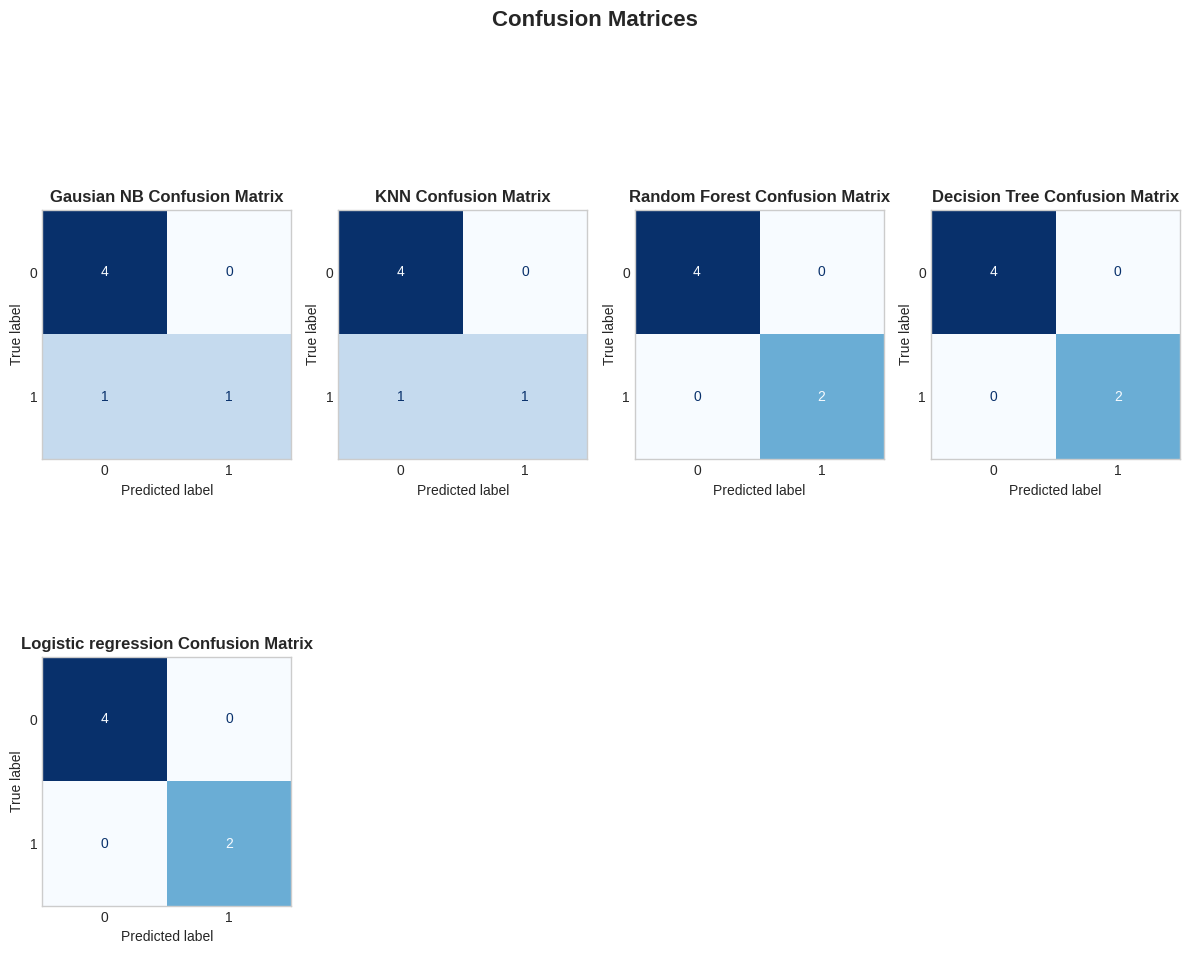


--- ROC Curves ---
Skipping: No probabilities or results_df.

--- Precision-Recall Curves ---


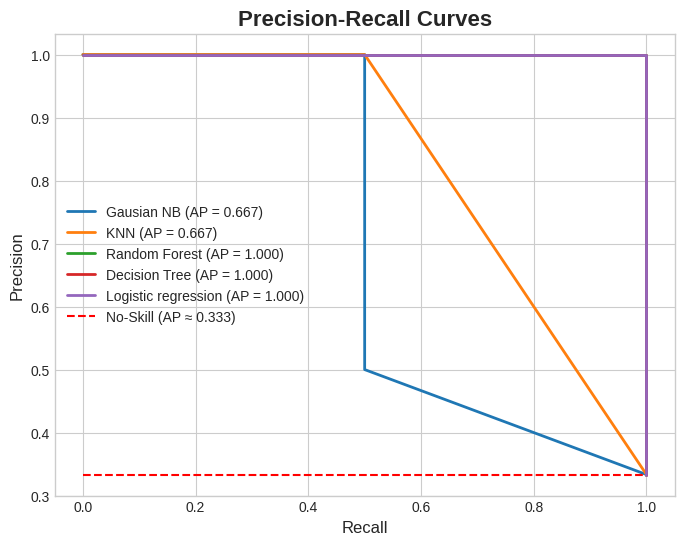


--- Visualization Done ---


In [ ]:
# to visualize classifier's confusion matrices, ROC curve, precision-recall curve and model comparison

predictions = {}
probabilities = {}
models = {
    "Gausian NB": nb_pipeline,
    "KNN": knn_pipeline,
    "Random Forest": rf_pipeline,
    "Decision Tree": dt_pipeline,
    "Logistic regression": lr_pipeline

}

# Generating predictions based on previousley trained classifiers
print("\n--- Generating Predictions ---")
for name, model_pipeline in models.items():
    print(f"Predicting with {name}...")
    try:
        if not hasattr(model_pipeline.steps[-1][1], 'classes_'):
            raise NotFittedError(f"Model '{name}' not fitted.")

        y_pred = model_pipeline.predict(X_test)
        y_prob = model_pipeline.predict_proba(X_test)[:, 1] if hasattr(model_pipeline, 'predict_proba') else None
        if y_prob is None:
            print(f"Warning: No predict_proba for {name}.")

        predictions[name] = y_pred
        if y_prob is not None:
            probabilities[name] = y_prob

    except NotFittedError as nfe:
        print(f"Skipping {name}: Not fitted. {nfe}")
    except AttributeError as ae:
        print(f"Attribute error with {name}: {ae}")
    except Exception as e:
        print(f"Error with {name}: {e}")

print("Done generating predictions.")

# Plotting Bar chart of performance matrices-----------
print("\n--- Plotting Metrics ---")
if 'results_df' in locals() and not results_df.empty:
    df_melted = results_df.reset_index().melt(id_vars='index', var_name='Metric', value_name='Score')
    df_melted.rename(columns={'index': 'Model'}, inplace=True)

    plt.figure(figsize=(14, 8))
    ax = sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette='viridis')
    plt.title('Model Performance Comparison', fontsize=16, fontweight='bold')
    plt.ylim(0, 1.05)

    for p in ax.patches:
        h = p.get_height()
        if h and h > 0.0001:
            ax.annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h), ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=9)

    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.show()
else:
    print("Skipping bar chart: 'results_df' missing or empty.")

# --- Plotting Confusion Matrices ---
print("\n--- Confusion Matrices ---")
if predictions:
    fig, axes = plt.subplots(2, 4, figsize=(12, 10))
    axes = axes.flatten()
    plotted = 0

    for i, model_name in enumerate(models.keys()):
        if model_name not in predictions:
            if i < len(axes): axes[i].set_visible(False)
            continue
        if i >= len(axes): break

        cm = confusion_matrix(y_test, predictions[model_name])
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
        disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
        axes[i].set_title(f'{model_name} Confusion Matrix', fontsize=12, fontweight='bold')
        axes[i].grid(False)
        plotted += 1

    for j in range(plotted, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle('Confusion Matrices', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()
else:
    print("Skipping: No predictions.")

# --- Plotting ROC Curves ---
print("\n--- ROC Curves ---")
if probabilities and 'results_df' in locals() and not results_df.empty:
    plt.figure(figsize=(8, 6))
    for model_name in probabilities:
        if model_name not in results_df.index:
            print(f"Skipping ROC for {model_name}: No metrics.")
            continue

        fpr, tpr, _ = roc_curve(y_test, probabilities[model_name])
        roc_auc = results_df.loc[model_name, 'ROC AUC'] if 'ROC AUC' in results_df.columns else None
        label = f'{model_name} (AUC = {roc_auc:.3f})' if roc_auc else model_name
        plt.plot(fpr, tpr, label=label, linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.500)', linewidth=1)
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curves', fontsize=16, fontweight='bold')
    plt.legend(loc="lower right", fontsize=10)
    plt.grid(True)
    plt.show()
else:
    print("Skipping: No probabilities or results_df.")

# --- Plotting Precision-Recall Curves ---
print("\n--- Precision-Recall Curves ---")
if probabilities:
    plt.figure(figsize=(8, 6))
    base_rate = y_test.mean()

    for model_name in probabilities:
        precision, recall, _ = precision_recall_curve(y_test, probabilities[model_name])
        avg_precision = average_precision_score(y_test, probabilities[model_name])
        plt.plot(recall, precision, label=f'{model_name} (AP = {avg_precision:.3f})', linewidth=2)

    plt.plot([0, 1], [base_rate, base_rate], 'r--', label=f'No-Skill (AP ≈ {base_rate:.3f})', linewidth=1.5)
    plt.xlabel('Recall', fontsize=12)
    plt.ylabel('Precision', fontsize=12)
    plt.title('Precision-Recall Curves', fontsize=16, fontweight='bold')
    plt.legend(loc="best", fontsize=10)
    plt.grid(True)
    plt.show()
else:
    print("Skipping: No probabilities.")

print("\n--- Visualization Done ---")
